# 01 EDA dan Preprocessing - Konsumsi Pangan Kabupaten/Kota (2024-2025)

**Tujuan:** menyiapkan data yang bersih, terdokumentasi, dan siap dimodelkan, sekaligus menentukan fitur apa yang layak dipakai.

| Hal | Keputusan |
|---|---|
| Periode | 1.028 baris = 514 wilayah × 2 tahun |
| Fitur dasar | 8 kelompok pangan dari baris total, kg/kapita/tahun |

**Alur:** A) EDA data mentah → B) Preprocessing → C) EDA data bersih untuk keputusan fitur → D) Fitur dan penskalaan → paket data siap.



In [ ]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, spearmanr
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 170); pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")


KANDIDAT_FOLDER = ["/content/data"]   # tempat mencari file CSV
TAHUN_PAKAI = [2024, 2025]        # seluruh data 2024-2025
TAHUN_ACUAN = 2025                # tahun acuan untuk kode dan nama wilayah
KONVERSI_KE_GRAM_HARI = True      # satuan asli kg/kapita/tahun
PSEUDO_GRAM = 0.1                 # pengganti nol untuk transformasi log-rasio (gram/hari)

# Standar PPH Nasional (gram/kapita/hari; AKE 2.000 kkal; Harmonisasi PPH, BKP 2013; jumlah 870 g)
PPH = {"padi-padian": 275, "umbi-umbian": 100, "pangan hewani": 150, "minyak dan lemak": 20,
       "buah/biji berminyak": 10, "kacang-kacangan": 35, "gula": 30, "sayur dan buah": 250}
FITUR_DASAR = list(PPH)           # 8 kelompok pangan (urutan PPH)

## 1. Load Dataset
Semua kolom dibaca sebagai **teks** (`dtype=str`) agar nilai aneh seperti `-`, spasi, atau `#REF!` tidak hilang diam-diam saat dikonversi. Pemisah kolom (`;` atau `,`) dideteksi otomatis.

In [ ]:
def cari_file():
    for folder in KANDIDAT_FOLDER:
        for p in sorted(glob.glob(os.path.join(folder, "*.csv"))):
            if os.path.basename(p).lower().replace(" ", "_").startswith("rata-rata_konsumsi_per_jenis_pangan"):
                return p
    raise FileNotFoundError("File CSV konsumsi tidak ditemukan. Letakkan di salah satu folder pada KANDIDAT_FOLDER.")

DATA_PATH = cari_file()
with open(DATA_PATH, encoding="utf-8-sig") as f:
    _header = f.readline()
SEP = ";" if _header.count(";") > _header.count(",") else ","          # deteksi pemisah kolom otomatis
raw = pd.read_csv(DATA_PATH, sep=SEP, encoding="utf-8-sig", dtype=str)  # semua dibaca sebagai teks
print("File    :", os.path.basename(DATA_PATH)); print("Pemisah :", repr(SEP)); print("Ukuran  :", raw.shape)
raw.head()

File    : Rata-rata Konsumsi per Jenis Pangan Penduduk Indonesia Kabupaten Kota Tahun 2025.csv
Pemisah : ';'
Ukuran  : (87380, 8)


,No,Tahun,Kode_Wilayah,Provinsi,Kabupaten_Kota,Kelompok_Bahan_Pangan,Komoditas,Konsumsi_Pangan
0,1,2025,3101,DKI Jakarta,Administrasi Kepulauan Seribu,Padi-Padian,Padi-Padian,102
1,2,2025,3101,DKI Jakarta,Administrasi Kepulauan Seribu,Padi-Padian,Beras,88.6
2,3,2025,3101,DKI Jakarta,Administrasi Kepulauan Seribu,Padi-Padian,Jagung,0.2
3,4,2025,3101,DKI Jakarta,Administrasi Kepulauan Seribu,Padi-Padian,Terigu,13.1
4,5,2025,3101,DKI Jakarta,Administrasi Kepulauan Seribu,Umbi-umbian,Umbi-umbian,9.3


# BAGIAN A - EDA Data Mentah
## A1. Struktur Dataset
Cek jumlah baris dan kolom, tipe data, dan jumlah nilai unik. Kolom `Tahun`, `Provinsi`, dan `Kelompok_Bahan_Pangan` yang nilai uniknya lebih banyak dari seharusnya adalah petunjuk awal adanya penulisan yang tidak konsisten.

In [ ]:
print("Kolom:", raw.columns.tolist())
raw.info()
print("\nJumlah nilai unik per kolom:")
print(raw.nunique().to_string())

Kolom: ['No', 'Tahun', 'Kode_Wilayah', 'Provinsi', 'Kabupaten_Kota', 'Kelompok_Bahan_Pangan', 'Komoditas', 'Konsumsi_Pangan']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87380 entries, 0 to 87379
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   No                     87380 non-null  object
 1   Tahun                  87363 non-null  object
 2   Kode_Wilayah           87363 non-null  object
 3   Provinsi               87363 non-null  object
 4   Kabupaten_Kota         87363 non-null  object
 5   Kelompok_Bahan_Pangan  87363 non-null  object
 6   Komoditas              87363 non-null  object
 7   Konsumsi_Pangan        87362 non-null  object
dtypes: object(8)
memory usage: 5.3+ MB

Jumlah nilai unik per kolom:
No                       87364
Tahun                        5
Kode_Wilayah               540
Provinsi                    40
Kabupaten_Kota             515
Kelompok_Bahan_Pangan       10


## A2. Missing Value
Ada dua jenis "kosong": **NaN asli** dan **token pengganti** (`-`, spasi, `#REF!`) yang tampak terisi tetapi tidak berisi data. Keduanya dihitung. Baris yang seluruh isinya kosong biasanya sisa error Excel.

,NaN asli,"Token pengganti (-, spasi, #REF!)",Total kosong,Persen (%)
No,0,17,17,0.019
Tahun,17,0,17,0.019
Kode_Wilayah,17,0,17,0.019
Provinsi,17,0,17,0.019
Kabupaten_Kota,17,0,17,0.019
Kelompok_Bahan_Pangan,17,0,17,0.019
Komoditas,17,0,17,0.019
Konsumsi_Pangan,18,8,26,0.030


Baris yang seluruh isinya kosong (selain kolom No): 17 | isi kolom No: ['#REF!']
Baris beridentitas lengkap tetapi nilai konsumsi kosong/token pengganti: 9
Per tahun: {'2021': 4, '2022': 4, '2023': 1}


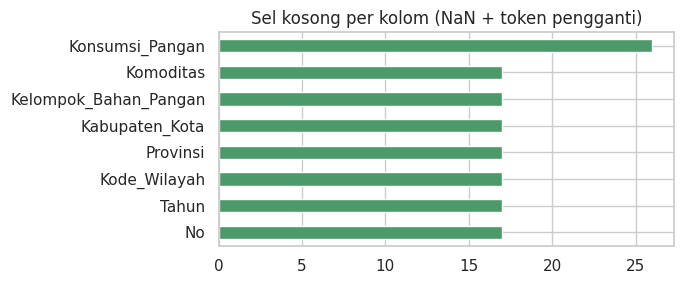

In [ ]:
TOKEN_KOSONG = {"", "-", "nan", "na", "n/a", "#ref!", "#n/a", "null"}

def token_pengganti(s):
    return (~s.isna()) & s.astype(str).str.strip().str.lower().isin(TOKEN_KOSONG)

miss = pd.DataFrame({"NaN asli": raw.isna().sum(), "Token pengganti (-, spasi, #REF!)": raw.apply(token_pengganti).sum()})
miss["Total kosong"] = miss.sum(axis=1)
miss["Persen (%)"] = (miss["Total kosong"] / len(raw) * 100).round(3)
display(miss)

kosong_total = raw[raw.drop(columns="No").isna().all(axis=1)]
print(f"Baris yang seluruh isinya kosong (selain kolom No): {len(kosong_total)} | isi kolom No: {kosong_total['No'].unique()}")
nilai_bermasalah = raw[raw["Tahun"].notna() & (raw["Konsumsi_Pangan"].isna() | token_pengganti(raw["Konsumsi_Pangan"]))]
print(f"Baris beridentitas lengkap tetapi nilai konsumsi kosong/token pengganti: {len(nilai_bermasalah)}")
print("Per tahun:", nilai_bermasalah["Tahun"].value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(7, 3))
miss["Total kosong"].sort_values().plot.barh(ax=ax, color="#4c9a6a"); ax.set_title("Sel kosong per kolom (NaN + token pengganti)")
plt.tight_layout(); plt.show()

## A3. Data Duplikat
Duplikat persis diperiksa lalu dicek apakah benar-benar data ganda atau sekadar baris kosong yang identik satu sama lain.

In [ ]:
dup = raw[raw.duplicated(keep=False)]
print("Salinan berlebih (duplikat persis):", raw.duplicated().sum(), "| baris yang terlibat dalam duplikasi:", len(dup))
print("Dari baris yang terlibat, yang seluruh isinya kosong (#REF!):", int(dup.drop(columns="No").isna().all(axis=1).sum()), "dari", len(dup))
print("=> Duplikat ini bukan data ganda sungguhan, melainkan baris kosong hasil error Excel.")

Salinan berlebih (duplikat persis): 16 | baris yang terlibat dalam duplikasi: 17
Dari baris yang terlibat, yang seluruh isinya kosong (#REF!): 17 dari 17
=> Duplikat ini bukan data ganda sungguhan, melainkan baris kosong hasil error Excel.


## A4. Konsistensi Kategori
Nama kelompok dan komoditas yang ditulis dengan huruf besar/kecil atau spasi berbeda dianggap kategori berbeda oleh komputer. Jumlah nama unik per tahun **seharusnya sama** (34 komoditas); selisihnya menunjukkan variasi penulisan.

In [ ]:
def norm_teks(s):
    return s.astype(str).str.replace(r"\s+", " ", regex=True).str.strip().str.lower()

d = raw[raw["Tahun"].notna()].copy()
d["Tahun"] = d["Tahun"].astype(float).astype(int)
d["Kode_Wilayah"] = d["Kode_Wilayah"].astype(float).astype(int)
d["kelompok"] = norm_teks(d["Kelompok_Bahan_Pangan"]); d["komoditas"] = norm_teks(d["Komoditas"])

print("Variasi penulisan KELOMPOK:", d["Kelompok_Bahan_Pangan"].nunique(), "(mentah) ->", d["kelompok"].nunique(), "(setelah normalisasi)")
display(pd.DataFrame({"komoditas unik (mentah)": d.groupby("Tahun")["Komoditas"].nunique(),
                      "komoditas unik (setelah normalisasi)": d.groupby("Tahun")["komoditas"].nunique()}))
var = d.groupby("komoditas")["Komoditas"].agg(lambda s: sorted(s.unique())); var = var[var.map(len) > 1]
print("Contoh komoditas dengan penulisan bervariasi:")
for k, v in list(var.items())[:5]: print(f"  {k!r:22} <- {v}")

Variasi penulisan KELOMPOK: 10 (mentah) -> 8 (setelah normalisasi)


,komoditas unik (mentah),komoditas unik (setelah normalisasi)
Tahun,,
2021,34,34
2022,34,34
2023,59,34
2024,43,34
2025,34,34


Contoh komoditas dengan penulisan bervariasi:
  'buah/biji berminyak'  <- ['Buah/Biji Berminyak', 'Buah/Biji Berminyak ', 'Buah/biji Berminyak', 'Buah/biji berminyak']
  'daging ruminansia'    <- ['Daging Ruminansia', 'Daging ruminansia']
  'gula'                 <- ['Gula', 'Gula ', 'Gula  ', 'gula']
  'gula merah'           <- ['Gula Merah', 'Gula merah']
  'gula pasir'           <- ['Gula Pasir', 'Gula pasir']


## A5. Cakupan Tahun dan Wilayah
Dua pertanyaan:
(1) apakah jumlah wilayah konsisten tiap tahun,  
(2) apakah **kode wilayah** menunjuk wilayah yang sama antartahun. Hasilnya menjadi dasar memilih 2024–2025 saja: tahun lain tidak lengkap dan kodenya dipakai ulang untuk wilayah berbeda.

,baris,n_kode,n_kabupaten,n_provinsi
Tahun,,,,
2021,17460,480,514,34
2022,17476,479,514,35
2023,17475,513,514,35
2024,17476,514,514,38
2025,17476,514,514,38


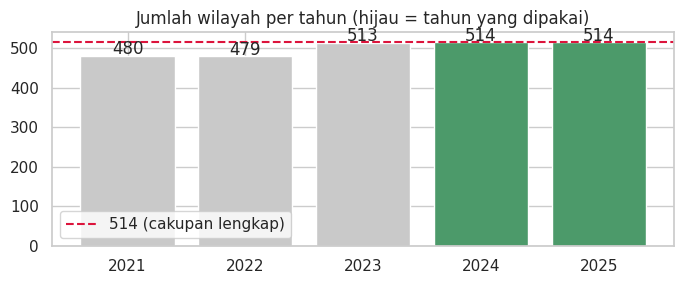

Pada [2024, 2025]: kode wilayah yang menunjuk >1 nama = 0
Pada seluruh tahun: kode wilayah yang menunjuk >1 nama = 46 dari 540


In [ ]:
cov = d.groupby("Tahun").agg(baris=("Tahun", "size"), n_kode=("Kode_Wilayah", "nunique"),
                              n_kabupaten=("Kabupaten_Kota", "nunique"), n_provinsi=("Provinsi", "nunique"))
display(cov)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(cov.index.astype(str), cov["n_kode"], color=["#c9c9c9" if t not in TAHUN_PAKAI else "#4c9a6a" for t in cov.index])
ax.axhline(514, color="crimson", ls="--", label="514 (cakupan lengkap)")
for x, v in zip(cov.index.astype(str), cov["n_kode"]): ax.text(x, v + 4, str(v), ha="center")
ax.set_title("Jumlah wilayah per tahun (hijau = tahun yang dipakai)"); ax.legend(); plt.tight_layout(); plt.show()

kn = d[d.Tahun.isin(TAHUN_PAKAI)].groupby("Kode_Wilayah")["Kabupaten_Kota"].nunique()
print(f"Pada {TAHUN_PAKAI}: kode wilayah yang menunjuk >1 nama = {(kn > 1).sum()}")
kn_all = d.groupby("Kode_Wilayah")["Kabupaten_Kota"].nunique()
print(f"Pada seluruh tahun: kode wilayah yang menunjuk >1 nama = {(kn_all > 1).sum()} dari {len(kn_all)}")

## A6. Nilai Konsumsi: Numerik, Negatif, Nol, dan Nilai Tak Wajar
- **Nol** adalah nilai sah (komoditas tidak dikonsumsi di wilayah itu), jadi tidak dibuang.
- **Negatif** tidak mungkin dan harus ditangani bila ada.
- Nilai **di atas 1.000** menandakan titik desimal hilang; tabel pembanding memperlihatkan masalah ini terkonsentrasi di tahun lama, bukan di 2024–2025.

In [ ]:
d["nilai"] = pd.to_numeric(d["Konsumsi_Pangan"].str.strip().replace({"-": np.nan, "": np.nan}), errors="coerce")
dp = d[d.Tahun.isin(TAHUN_PAKAI)]
print("Tahun yang dipakai:", TAHUN_PAKAI)
print("  nilai tak terbaca sebagai angka:", int(dp["nilai"].isna().sum()), "| nilai negatif:", int((dp["nilai"] < 0).sum()),
      "| nilai nol:", int((dp["nilai"] == 0).sum()), f"({(dp['nilai'] == 0).mean():.1%})")
print("Seluruh tahun (pembanding):")
display(d.groupby("Tahun")["nilai"].agg(kosong=lambda s: int(s.isna().sum()), negatif=lambda s: int((s < 0).sum()),
                                         di_atas_1000=lambda s: int((s > 1000).sum()), maks="max").round(1))

Tahun yang dipakai: [2024, 2025]
  nilai tak terbaca sebagai angka: 0 | nilai negatif: 0 | nilai nol: 1538 (4.4%)
Seluruh tahun (pembanding):


,kosong,negatif,di_atas_1000,maks
Tahun,,,,
2021,4,0,16,111060.0
2022,4,0,136,803869.0
2023,1,1,37,103800.0
2024,0,0,0,465.1
2025,0,0,0,438.7


## A7. Struktur Hierarki: Baris Total vs Baris Komoditas
Tiap kelompok pangan punya satu baris **total** (nama komoditas = nama kelompok) dan beberapa baris **komoditas penyusun**. Hipotesis: total = jumlah komponen. Jika benar, menjumlahkan **semua** baris menghitung dua kali (rasio sekitar 2,0). Fitur yang benar adalah **baris total saja**.

In [ ]:
d["is_total"] = d["komoditas"] == d["kelompok"]
dd = d[d.Tahun.isin(TAHUN_PAKAI)]
tot = dd[dd.is_total].groupby(["Tahun", "Kode_Wilayah", "kelompok"])["nilai"].sum().rename("baris_total")
komp = dd[~dd.is_total].groupby(["Tahun", "Kode_Wilayah", "kelompok"])["nilai"].sum().rename("jumlah_komponen")
semua = dd.groupby(["Tahun", "Kode_Wilayah", "kelompok"])["nilai"].sum().rename("jumlah_semua_baris")
cek = pd.concat([tot, komp, semua], axis=1)
cek["selisih"] = (cek.baris_total - cek.jumlah_komponen).abs(); cek["rasio_semua_vs_total"] = cek.jumlah_semua_baris / cek.baris_total
display(cek.groupby("kelompok").agg(selisih_maks=("selisih", "max"), rasio_rata2=("rasio_semua_vs_total", "mean")).round(3))
print("Selisih maksimum total vs jumlah komponen (seharusnya hanya pembulatan):", round(cek.selisih.max(), 3))

,selisih_maks,rasio_rata2
kelompok,,
buah/biji berminyak,0.1,1.999
gula,0.1,2.000
kacang-kacangan,0.2,2.000
minyak dan lemak,0.1,2.000
padi-padian,0.1,2.000
pangan hewani,0.2,2.000
sayur dan buah,0.1,2.000
umbi-umbian,0.2,2.000


Selisih maksimum total vs jumlah komponen (seharusnya hanya pembulatan): 0.2


## A8. Ringkasan Temuan EDA Data Mentah
Tabel berikut dipakai sebagai bahan dokumentasi: masalah, buktinya, dan cara penanganannya di bagian B.

In [ ]:
n_komoditas_normal = d["komoditas"].nunique()
temuan = pd.DataFrame([
    ("Baris kosong total (#REF!)", f"{len(kosong_total)} baris", "Hapus"),
    ("Baris duplikat persis", f"{raw.duplicated().sum()} baris (semuanya baris kosong)", "Hapus (ikut tersaring)"),
    ("Penulisan komoditas tidak konsisten", f"{raw['Komoditas'].nunique()} nama mentah -> {n_komoditas_normal} nama", "Normalisasi teks"),
    ("Baris total dan komponen ikut dijumlahkan", "Total = jumlah komponen; menjumlah semua baris membuat nilai 2x", "Pakai baris total saja"),
    ("Cakupan wilayah tidak lengkap & kode dipakai ulang di tahun lain", f"{cov['n_kode'].min()}-{cov['n_kode'].max()} wilayah per tahun", f"Pakai {TAHUN_PAKAI} saja; samakan wilayah via nama+provinsi"),
    ("Nilai kosong/negatif pada tahun yang dipakai", f"{int(dp['nilai'].isna().sum())} kosong, {int((dp['nilai'] < 0).sum())} negatif", "Tidak perlu imputasi (dijaga oleh pemeriksaan)"),
], columns=["Masalah", "Bukti", "Penanganan"])
display(temuan.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,Masalah,Bukti,Penanganan
0,Baris kosong total (#REF!),17 baris,Hapus
1,Baris duplikat persis,16 baris (semuanya baris kosong),Hapus (ikut tersaring)
2,Penulisan komoditas tidak konsisten,62 nama mentah -> 34 nama,Normalisasi teks
3,Baris total dan komponen ikut dijumlahkan,Total = jumlah komponen; menjumlah semua baris membuat nilai 2x,Pakai baris total saja
4,Cakupan wilayah tidak lengkap & kode dipakai ulang di tahun lain,479-514 wilayah per tahun,"Pakai [2024, 2025] saja; samakan wilayah via nama+provinsi"
5,Nilai kosong/negatif pada tahun yang dipakai,"0 kosong, 0 negatif",Tidak perlu imputasi (dijaga oleh pemeriksaan)


# BAGIAN B - Preprocessing
Setiap langkah dicatat di `log_penanganan` agar bisa dilaporkan. Preprocessing dimulai ulang dari data mentah (`raw`) supaya notebook ini bisa direproduksi.

## B1–B3. Hapus Baris Kosong, Normalisasi Teks, Filter Tahun, Konversi Numerik
- Baris kosong (#REF!) dihapus **sebelum** duplikat dicek, sehingga duplikat tersisa = 0.
- Komoditas dipetakan ke kelompok kanonik berdasarkan tahun acuan.
- Pemeriksaan (`assert`) menghentikan notebook bila ada nilai kosong atau negatif pada tahun yang dipakai, agar tidak ada imputasi diam-diam.

In [ ]:
log_penanganan = []
def catat(langkah, jumlah, keterangan=""):
    log_penanganan.append({"langkah": langkah, "jumlah": jumlah, "keterangan": keterangan})

df = raw.copy()
n0 = len(df)
df = df[df["Tahun"].notna() & df["Kode_Wilayah"].notna()].copy(); catat("B1 Hapus baris kosong (#REF!)", n0 - len(df))
n1 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "No"]); catat("B1 Hapus duplikat persis", n1 - len(df))

df["Tahun"] = df["Tahun"].astype(float).astype(int); df["Kode_Wilayah"] = df["Kode_Wilayah"].astype(float).astype(int)
for c in ["Provinsi", "Kabupaten_Kota"]:
    df[c] = df[c].str.replace(r"\s+", " ", regex=True).str.strip()
df["kelompok"] = norm_teks(df["Kelompok_Bahan_Pangan"]); df["komoditas"] = norm_teks(df["Komoditas"])
df["is_total"] = df["komoditas"] == df["kelompok"]

n2 = len(df); df = df[df["Tahun"].isin(TAHUN_PAKAI)].copy(); catat(f"B2 Filter tahun {TAHUN_PAKAI}", n2 - len(df), "tahun lain dikeluarkan")
peta_kom_kel = df[df.Tahun == TAHUN_ACUAN].groupby("komoditas")["kelompok"].agg(lambda s: s.mode().iloc[0]).to_dict()
assert set(df["komoditas"]) <= set(peta_kom_kel), "Ada komoditas yang tidak ada di tahun acuan"
assert set(df[df.is_total]["kelompok"]) == set(FITUR_DASAR), "8 kelompok pada data tidak sama dengan PPH"
df["kelompok"] = df["komoditas"].map(peta_kom_kel)
catat("B2 Komoditas kanonik", len(peta_kom_kel), "termasuk 8 baris total")

df["nilai"] = pd.to_numeric(df["Konsumsi_Pangan"].str.strip().replace({"-": np.nan, "": np.nan}), errors="coerce")
catat("B3 Nilai kosong/bukan angka", int(df["nilai"].isna().sum())); catat("B3 Nilai negatif", int((df["nilai"] < 0).sum()))
assert df["nilai"].notna().all() and (df["nilai"] >= 0).all(), \
    "Ada nilai kosong/negatif pada tahun yang dipakai. Gunakan rekonstruksi total = jumlah komponen seperti pada notebook 01 (B6)."
print("Baris tersisa:", len(df), "| komoditas unik:", df["komoditas"].nunique(), "| baris per tahun:", df.groupby("Tahun").size().to_dict())

Baris tersisa: 34952 | komoditas unik: 34 | baris per tahun: {2024: 17476, 2025: 17476}


## B4. Sinkronisasi Wilayah dan Uji Konsistensi
Wilayah antartahun disamakan lewat **nama dan provinsi** (bukan hanya kode) dengan tahun acuan sebagai patokan. Lalu identitas *total = jumlah komponen* diuji ulang pada data yang dipakai (toleransi pembulatan 0,5).

In [ ]:
ref = (df[df.Tahun == TAHUN_ACUAN][["Kode_Wilayah", "Provinsi", "Kabupaten_Kota"]].drop_duplicates().reset_index(drop=True))
assert ref["Kode_Wilayah"].is_unique, "Kode wilayah tahun acuan tidak unik"
kode_acuan = ref.set_index(["Provinsi", "Kabupaten_Kota"])["Kode_Wilayah"]
df["kode_acuan"] = [kode_acuan.get((p, k), np.nan) for p, k in zip(df["Provinsi"], df["Kabupaten_Kota"])]
tdk = df[df["kode_acuan"].isna()][["Tahun", "Provinsi", "Kabupaten_Kota"]].drop_duplicates()
print("Wilayah acuan:", len(ref), "| baris yang tidak bisa dipetakan:", len(tdk))
assert len(tdk) == 0, f"Wilayah tidak cocok antartahun:\n{tdk}"
df["kode_acuan"] = df["kode_acuan"].astype(int)
print("Wilayah per tahun:", df.groupby("Tahun")["kode_acuan"].nunique().to_dict())

kunci = ["Tahun", "kode_acuan", "kelompok"]
t_ = df[df.is_total].groupby(kunci)["nilai"].sum().rename("total"); k_ = df[~df.is_total].groupby(kunci)["nilai"].sum().rename("komponen")
chk = pd.concat([t_, k_], axis=1); chk["selisih"] = (chk["total"] - chk["komponen"]).abs()
print("Selisih maks total vs jumlah komponen:", round(chk.selisih.max(), 3), "| grup yang melanggar (>0,5):", int((chk.selisih > 0.5).sum()))
assert (chk.selisih <= 0.5).all(), "Identitas total = jumlah komponen dilanggar"
catat("B4 Grup yang melanggar total = jumlah komponen", int((chk.selisih > 0.5).sum()))

Wilayah acuan: 514 | baris yang tidak bisa dipetakan: 0
Wilayah per tahun: {2024: 514, 2025: 514}
Selisih maks total vs jumlah komponen: 0.2 | grup yang melanggar (>0,5): 0


## B5–B6. Tabel Lebar dan Konversi Satuan
Data diubah menjadi satu baris per (Tahun, Wilayah):
- `G`: 8 kelompok dari **baris total** (fitur dasar),
- `KOM`: 26 komoditas (untuk fitur turunan dan profiling),
- `meta`: identitas wilayah (bukan fitur).

Nilai dikonversi dari kg/kapita/tahun ke **gram/kapita/hari** (× 1000 / 365). Faktor ini tidak memengaruhi bentuk klaster setelah penskalaan, tetapi membuat nilai sebanding dengan standar gizi.

In [ ]:
FAKTOR = 1000 / 365 if KONVERSI_KE_GRAM_HARI else 1.0
SATUAN = "gram/kapita/hari" if KONVERSI_KE_GRAM_HARI else "kg/kapita/tahun"

def buat_wide(frame, level):
    s = frame[frame.is_total] if level == "kelompok" else frame[~frame.is_total]
    kol = "kelompok" if level == "kelompok" else "komoditas"
    assert not s.duplicated(["Tahun", "kode_acuan", kol]).any(), "Ada duplikat kunci"
    w = s.pivot_table(index=["Tahun", "kode_acuan"], columns=kol, values="nilai", aggfunc="first") * FAKTOR
    w.index.names = ["Tahun", "Kode_Wilayah"]
    return w

G = buat_wide(df, "kelompok")[FITUR_DASAR].round(3)              # fitur dasar: 8 kelompok
KOM = buat_wide(df, "komoditas").round(3)                        # 26 komoditas (untuk fitur turunan & profiling)
meta = ref.set_index("Kode_Wilayah").reindex(G.index.get_level_values("Kode_Wilayah")); meta.index = G.index
catat("B6 Konversi satuan", len(G), SATUAN)
print("Satuan akhir:", SATUAN); print("G (8 kelompok):", G.shape, "| KOM (komoditas):", KOM.shape, "| meta:", meta.shape)
G.head()

Satuan akhir: gram/kapita/hari
G (8 kelompok): (1028, 8) | KOM (komoditas): (1028, 26) | meta: (1028, 2)


kelompok            padi-padian  umbi-umbian  pangan hewani  minyak dan lemak  buah/biji berminyak  kacang-kacangan    gula  sayur dan buah
Tahun Kode_Wilayah                                                                                                                         
2024  1101              312.219       23.479        141.452            33.425               16.904           12.219  17.233         192.411
      1102              309.205       22.000        135.671            31.151               14.932           17.753   9.589         196.192
      1103              297.562       24.658        143.288            22.877                8.548           16.000  18.877         180.795
      1104              324.712       44.247        119.123            32.274                3.123           25.014  22.575         295.890
      1105              313.123       25.616        153.671            29.260                9.918           17.589  15.288         224.247

## B7. Validasi Hasil Preprocessing
Semua pemeriksaan harus lolos sebelum data dilanjutkan: jumlah baris, wilayah per tahun, jumlah fitur, tidak ada NaN atau negatif, dan kunci unik.

In [ ]:
valid = pd.DataFrame({
    "Pemeriksaan": ["Jumlah baris (wilayah x tahun)", "Wilayah per tahun", "Jumlah fitur dasar", "Ada NaN", "Ada nilai negatif",
                    "Kunci (Tahun, Kode) unik", "Total = jumlah komponen (selisih maks)"],
    "Hasil": [len(G), G.groupby(level="Tahun").size().to_dict(), G.shape[1], bool(G.isna().any().any()), bool((G < 0).any().any()),
              bool(G.index.is_unique), round(chk.selisih.max(), 3)],
    "Harapan": [f"{514 * len(TAHUN_PAKAI)}", "514 per tahun", "8", "False", "False", "True", "<= 0,5"]})
display(valid)
assert len(G) == 514 * len(TAHUN_PAKAI) and not G.isna().any().any() and G.index.is_unique

,Pemeriksaan,Hasil,Harapan
0,Jumlah baris (wilayah x tahun),1028,1028
1,Wilayah per tahun,"{2024: 514, 2025: 514}",514 per tahun
2,Jumlah fitur dasar,8,8
3,Ada NaN,False,False
4,Ada nilai negatif,False,False
5,"Kunci (Tahun, Kode) unik",True,True
6,Total = jumlah komponen (selisih maks),0.2,"<= 0,5"


# BAGIAN C - EDA Data Bersih untuk Keputusan Fitur
## C1. Distribusi dan Skewness
Skewness mengukur kemiringan sebaran. Nilai **|skew| > 2** berarti sangat miring (ekor panjang) dan perlu dipertimbangkan transformasi log. Kolom `persen_nol` menunjukkan seberapa sering suatu kelompok tidak dikonsumsi sama sekali.

,min,median,rata2,maks,std,skewness,persen_nol
kelompok,,,,,,,
padi-padian,36.38,289.01,289.92,450.14,50.02,-0.83,0.00
umbi-umbian,2.88,38.36,56.80,1274.25,105.14,7.78,0.00
pangan hewani,25.01,132.32,133.07,276.80,30.87,0.05,0.00
minyak dan lemak,9.34,27.97,27.87,49.32,5.49,-0.10,0.00
buah/biji berminyak,0.00,2.68,4.03,29.42,4.17,2.38,2.33
kacang-kacangan,1.37,20.27,21.71,58.82,9.53,0.41,0.00
gula,7.37,21.64,21.72,46.25,6.79,0.33,0.00
sayur dan buah,115.26,242.36,246.80,500.58,51.15,0.65,0.00


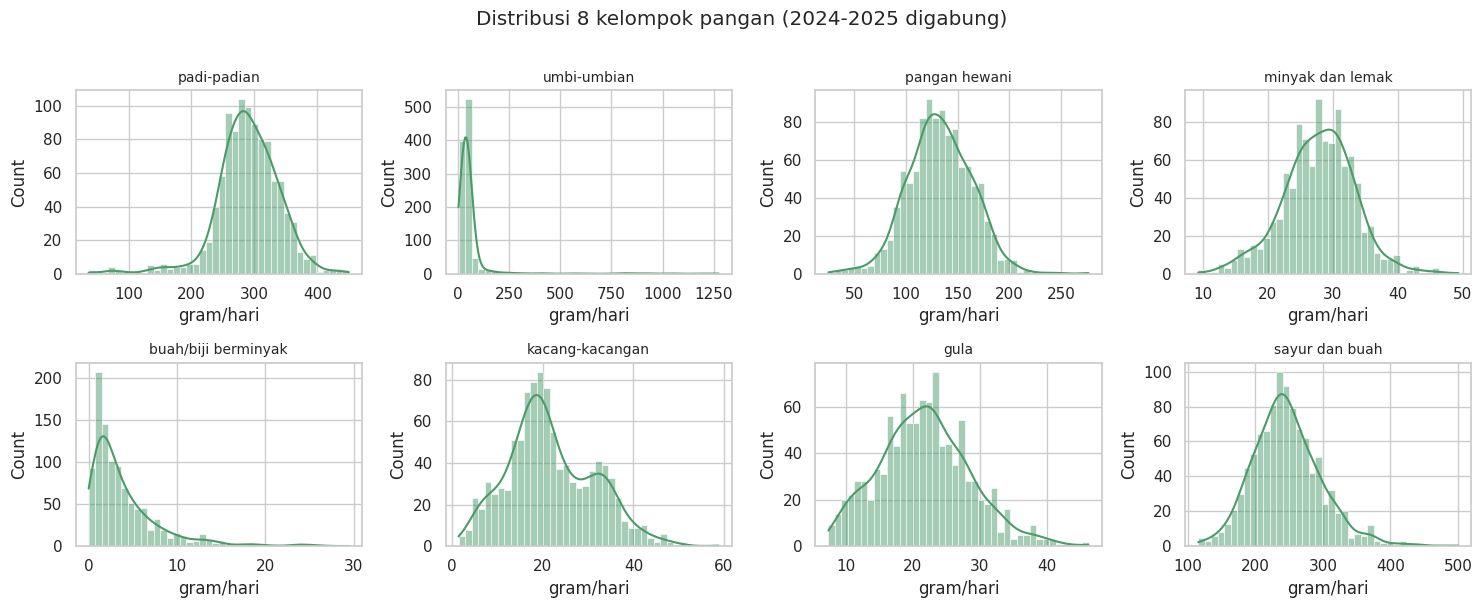

In [ ]:
stat = pd.DataFrame({"min": G.min(), "median": G.median(), "rata2": G.mean(), "maks": G.max(), "std": G.std(),
                     "skewness": G.apply(lambda s: skew(s)), "persen_nol": (G == 0).mean() * 100}).round(2)
display(stat)
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), FITUR_DASAR):
    sns.histplot(G[c], bins=40, kde=True, ax=ax, color="#4c9a6a"); ax.set_title(c, fontsize=10); ax.set_xlabel("gram/hari")
plt.suptitle("Distribusi 8 kelompok pangan (2024-2025 digabung)", y=1.01); plt.tight_layout(); plt.show()

## C2. Nilai Ekstrem (Outlier)
Aturan IQR: **ringan** di luar 1,5 × IQR, **ekstrem** di luar 3 × IQR. Pertanyaan kuncinya: apakah nilai ekstrem itu **kesalahan data** atau **pola nyata**? Buktinya dicari lewat konteks: wilayah mana yang ekstrem, dan apakah nilainya konsisten dengan kelompok lain (mis. umbi tinggi diiringi padi rendah).

Keputusan: nilai ekstrem yang terbukti pola nyata **tidak dibuang**, karena menghapusnya berarti menghapus wilayah yang justru perlu dipahami pemangku kepentingan. Dampaknya pada jarak Euclidean ditangani lewat varian penskalaan (bagian D).

,"outlier (1,5 x IQR)",ekstrem (3 x IQR),% ekstrem
kelompok,,,
padi-padian,34,8,0.8
umbi-umbian,71,52,5.1
pangan hewani,13,0,0.0
minyak dan lemak,20,0,0.0
buah/biji berminyak,66,23,2.2
kacang-kacangan,4,0,0.0
gula,10,0,0.0
sayur dan buah,25,2,0.2


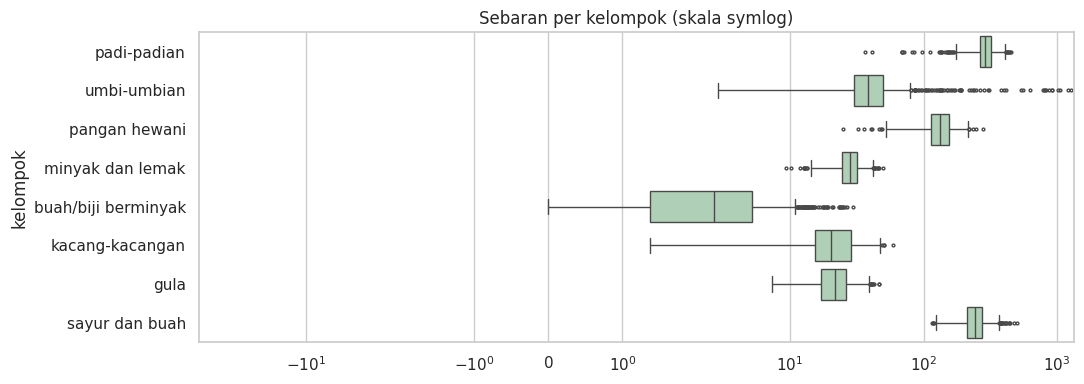

12 pengamatan dengan umbi-umbian tertinggi (apakah nilai ekstrem ini kesalahan data atau pola nyata?):


Provinsi      Kabupaten_Kota    umbi   padi
Tahun Kode_Wilayah                                                     
2024  9503          Papua Pegunungan            Yahukimo  1274.0   69.0
2025  9503          Papua Pegunungan            Yahukimo  1202.0   85.0
2024  9507          Papua Pegunungan          Lanny Jaya  1052.0  295.0
      9504          Papua Pegunungan            Tolikara  1013.0  176.0
2025  9504          Papua Pegunungan            Tolikara   923.0  130.0
2024  9505          Papua Pegunungan    Mamberamo Tengah   917.0   82.0
2025  9507          Papua Pegunungan          Lanny Jaya   864.0  253.0
      9508          Papua Pegunungan               Nduga   829.0   68.0
2024  9508          Papua Pegunungan               Nduga   812.0   71.0
2025  9505          Papua Pegunungan    Mamberamo Tengah   797.0   69.0
      9502          Papua Pegunungan  Pegunungan Bintang   779.0  112.0
2024  9502          Papua Pegunungan  Pegunungan Bintang   622.0   97.0

Korelasi Spearman umbi vs padi: -0.38 -> bila negatif kuat, umbi menggantikan beras (pola nyata, bukan salah ketik)


In [ ]:
q1, q3 = G.quantile(.25), G.quantile(.75); iqr = q3 - q1
ringan = ((G < q1 - 1.5 * iqr) | (G > q3 + 1.5 * iqr)).sum(); ekstrem = ((G < q1 - 3 * iqr) | (G > q3 + 3 * iqr)).sum()
display(pd.DataFrame({"outlier (1,5 x IQR)": ringan, "ekstrem (3 x IQR)": ekstrem, "% ekstrem": (ekstrem / len(G) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(11, 4)); sns.boxplot(data=G, orient="h", color="#a9d6b4", ax=ax, fliersize=2)
ax.set_xscale("symlog"); ax.set_title("Sebaran per kelompok (skala symlog)"); plt.tight_layout(); plt.show()

top = G["umbi-umbian"].nlargest(12)
bukti = meta.loc[top.index, ["Provinsi", "Kabupaten_Kota"]].assign(umbi=top.round(0), padi=G.loc[top.index, "padi-padian"].round(0))
print("12 pengamatan dengan umbi-umbian tertinggi (apakah nilai ekstrem ini kesalahan data atau pola nyata?):")
display(bukti)
print("Korelasi Spearman umbi vs padi:", round(spearmanr(G["umbi-umbian"], G["padi-padian"])[0], 2),
      "-> bila negatif kuat, umbi menggantikan beras (pola nyata, bukan salah ketik)")

## C3. Uji Satuan
Metadata tidak menyebut satuan. Hipotesis **kg/kapita/tahun** diuji dengan membandingkan median (dikonversi ke gram/hari) terhadap standar PPH: rasio padi-padian dan sayur-buah harus mendekati 1. Ini **inferensi**, bukan fakta dari sumber, dan harus dikonfirmasi ke penerbit data.

In [ ]:
uji = pd.DataFrame({"median_gram_per_hari": G.median().round(0), "standar_PPH": pd.Series(PPH)})
uji["rasio"] = (uji.median_gram_per_hari / uji.standar_PPH).round(2)
display(uji)
print("Jika satuan asli bukan kg/kapita/tahun, rasio padi-padian dan sayur-buah tidak akan mendekati 1.")

,median_gram_per_hari,standar_PPH,rasio
padi-padian,289.0,275,1.05
umbi-umbian,38.0,100,0.38
pangan hewani,132.0,150,0.88
minyak dan lemak,28.0,20,1.40
buah/biji berminyak,3.0,10,0.30
kacang-kacangan,20.0,35,0.57
gula,22.0,30,0.73
sayur dan buah,242.0,250,0.97


Jika satuan asli bukan kg/kapita/tahun, rasio padi-padian dan sayur-buah tidak akan mendekati 1.


## C4. Korelasi dan Kolinearitas Fitur Dasar
- **Korelasi Spearman** melihat hubungan antarfitur tanpa terpengaruh nilai ekstrem.
- **VIF** (Variance Inflation Factor) mengukur seberapa besar sebuah fitur bisa "ditebak" dari fitur lain. VIF < 10 dianggap aman; VIF tak hingga berarti fitur itu kombinasi linear tepat dari yang lain.
Hasil ini menjadi pembanding saat menilai kandidat fitur tambahan di bagian D.

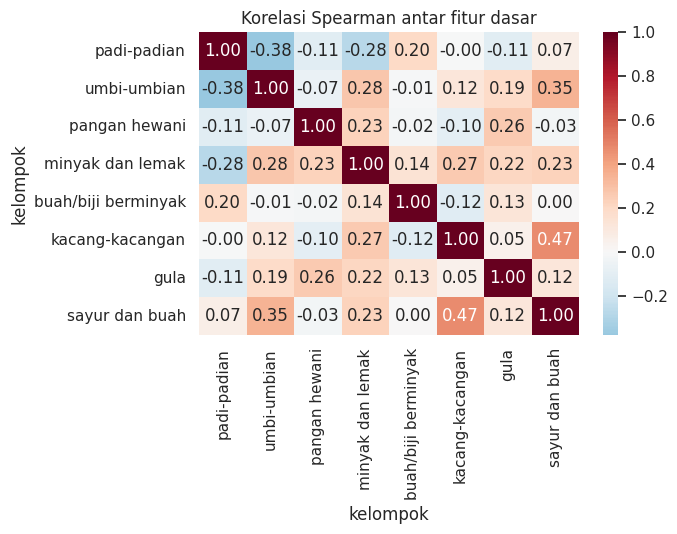

,VIF (8 fitur dasar)
padi-padian,1.69
umbi-umbian,2.07
pangan hewani,1.33
minyak dan lemak,1.34
buah/biji berminyak,1.12
kacang-kacangan,1.51
gula,1.11
sayur dan buah,1.50


In [ ]:
def vif(df_):
    out = {}
    for c in df_.columns:
        y = df_[c].values; Xb = np.column_stack([np.ones(len(df_)), df_.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(Xb, y, rcond=None)
        r2 = 1 - ((y - Xb @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(G.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Korelasi Spearman antar fitur dasar"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"VIF (8 fitur dasar)": vif(G).round(2)}))

## C5. Efek Tahun dan Risiko "Kembar" (Karena Data Ditumpuk)
Dua pemeriksaan yang penting karena 2024 dan 2025 digabung:

1. **Efek tahun:** selisih standar (Cohen's d) antara rata-rata 2025 dan 2024. Nilai |d| > 0,5 berarti satu fitur bergeser besar antartahun. Jika ada, penskalaan per tahun layak dicoba (bagian D).
2. **Efek "kembar":** tiap wilayah muncul dua kali (2024 dan 2025). Jika kembar sering menjadi tetangga terdekat, setiap titik selalu punya tetangga dekat yang satu klaster dengannya, sehingga silhouette, DBI, dan CHI tampak **lebih baik dari kenyataan**. Ukurannya dilaporkan di sini agar metrik di Langkah 2 dibaca dengan hati-hati. Pembandingnya adalah data rata-rata per wilayah (`G_RATA`).

In [ ]:
d_smd = {}
for c in FITUR_DASAR:
    a, b = G.xs(TAHUN_PAKAI[0], level="Tahun")[c], G.xs(TAHUN_PAKAI[1], level="Tahun")[c]
    d_smd[c] = (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)
smd = pd.Series(d_smd).round(2)
print(f"Selisih standar (Cohen's d) rata-rata {TAHUN_PAKAI[1]} vs {TAHUN_PAKAI[0]} per fitur (|d| > 0,5 = pergeseran antartahun besar):")
display(smd.to_frame("d"))

Z = StandardScaler().fit_transform(G)
nbr = NearestNeighbors(n_neighbors=2).fit(Z).kneighbors(Z, return_distance=False)[:, 1]
kode = G.index.get_level_values("Kode_Wilayah").values
persen_kembar = (kode[nbr] == kode).mean() * 100
D = cdist(Z, Z); np.fill_diagonal(D, np.inf)
pos = pd.Series(np.arange(len(G)), index=G.index)
kembar_idx = np.array([pos[(t2, k)] for (t, k) in G.index for t2 in TAHUN_PAKAI if t2 != t])   # berlaku untuk 2 tahun
jarak_kembar = D[np.arange(len(G)), kembar_idx]
peringkat = (D < jarak_kembar[:, None]).sum(axis=1) + 1
print(f"\nTetangga terdekat adalah 'kembar'-nya sendiri (wilayah sama, tahun lain): {persen_kembar:.1f}% pengamatan")
print(f"Peringkat 'kembar' di antara {len(G) - 1} pengamatan lain: median = {np.median(peringkat):.0f}; masuk 5 terdekat = {(peringkat <= 5).mean() * 100:.1f}%")
print("Makin kecil peringkat, makin kuat efek 'kembar': tiap titik punya tetangga dekat yang pasti satu klaster dengannya,")
print("sehingga silhouette/DBI/CHI bisa tampak lebih baik daripada kenyataan. Wajib diingat saat membaca metrik di Langkah 2.")

Selisih standar (Cohen's d) rata-rata 2025 vs 2024 per fitur (|d| > 0,5 = pergeseran antartahun besar):


,d
padi-padian,-0.28
umbi-umbian,0.05
pangan hewani,0.25
minyak dan lemak,0.21
buah/biji berminyak,-0.04
kacang-kacangan,0.24
gula,1.10
sayur dan buah,0.13



Tetangga terdekat adalah 'kembar'-nya sendiri (wilayah sama, tahun lain): 10.6% pengamatan
Peringkat 'kembar' di antara 1027 pengamatan lain: median = 20; masuk 5 terdekat = 24.9%
Makin kecil peringkat, makin kuat efek 'kembar': tiap titik punya tetangga dekat yang pasti satu klaster dengannya,
sehingga silhouette/DBI/CHI bisa tampak lebih baik daripada kenyataan. Wajib diingat saat membaca metrik di Langkah 2.


# BAGIAN D — Fitur dan Penskalaan
## D1. Feature Selection Dasar
Keputusan fitur dasar beserta alasannya:
- **8 kelompok pangan** (dari baris total) dipakai: bermakna gizi dan sesuai standar PPH.
- **Tahun dibuang**: penanda waktu, bukan sifat konsumsi.
- **Identitas wilayah dibuang**: hanya untuk profiling.
- **26 komoditas bukan fitur dasar**: jumlahnya sudah terwakili baris total, sehingga memasukkan keduanya menghitung ganda. Komoditas dipakai untuk fitur turunan dan profiling.

In [ ]:
alasan = pd.DataFrame([
    (c, "DIPAKAI", f"Kelompok PPH; bermakna gizi; dari baris total (standar {PPH[c]} g/hari)") for c in FITUR_DASAR
] + [
    ("Tahun", "DIBUANG", "Penanda waktu, bukan sifat konsumsi; bila dipakai, klaster akan memisahkan tahun"),
    ("Kode_Wilayah / Provinsi / Kabupaten_Kota", "DIBUANG", "Identitas; dipakai hanya untuk profiling dan penyambungan"),
    ("26 komoditas penyusun", "TIDAK dijadikan fitur dasar", "Jumlahnya sudah terwakili baris total; memasukkan keduanya menghitung ganda. Dipakai untuk fitur turunan dan profiling"),
], columns=["Kolom", "Keputusan", "Alasan"])
display(alasan.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("Fitur dasar:", FITUR_DASAR)

,Kolom,Keputusan,Alasan
0,padi-padian,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 275 g/hari)
1,umbi-umbian,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 100 g/hari)
2,pangan hewani,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 150 g/hari)
3,minyak dan lemak,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 20 g/hari)
4,buah/biji berminyak,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 10 g/hari)
5,kacang-kacangan,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 35 g/hari)
6,gula,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 30 g/hari)
7,sayur dan buah,DIPAKAI,Kelompok PPH; bermakna gizi; dari baris total (standar 250 g/hari)
8,Tahun,DIBUANG,"Penanda waktu, bukan sifat konsumsi; bila dipakai, klaster akan memisahkan tahun"
9,Kode_Wilayah / Provinsi / Kabupaten_Kota,DIBUANG,Identitas; dipakai hanya untuk profiling dan penyambungan


Fitur dasar: ['padi-padian', 'umbi-umbian', 'pangan hewani', 'minyak dan lemak', 'buah/biji berminyak', 'kacang-kacangan', 'gula', 'sayur dan buah']


## D2. Kandidat Fitur Turunan
Setiap kandidat harus punya **makna bagi pemangku kepentingan**, tidak sekadar menambah kolom.

| Kandidat | Rumus | Makna |
|---|---|---|
| `total_gram` | jumlah 8 kelompok | Besaran konsumsi total |
| `indeks_kesesuaian_pph` | rata-rata min(gram ÷ standar, 1) | Capaian terhadap standar gram PPH |
| `keragaman_shannon` | entropi Shannon proporsi 8 kelompok (0–1) | Keragaman komposisi piring |
| `rasio_umbi_vs_padi` | umbi ÷ (umbi + padi) | Ketergantungan umbi dibanding serealia |
| `porsi_beras_dlm_padi` | beras ÷ padi-padian | Dominasi beras dibanding jagung dan terigu |
| `porsi_ikan_dlm_hewani` | ikan ÷ pangan hewani | Peran ikan (pesisir vs daratan) |
| `porsi_buah_dlm_sayurbuah` | buah ÷ (sayur + buah) | Keseimbangan buah dan sayur |
| `porsi_sawit_dlm_minyak` | minyak sawit ÷ minyak dan lemak | Sawit vs kelapa dan minyak lain |
| `porsi_sagu_dlm_umbi` | sagu ÷ umbi-umbian | Peran sagu |

Catatan: indeks kesesuaian memakai standar PPH edisi AKE 2.000 kkal dan membatasi tiap kelompok maksimum 1, sehingga gula dan minyak tidak dihitung sebagai "target yang makin tinggi makin baik".

In [ ]:
def bagi(a, b):
    return (a / b.where(b > 1e-9)).astype(float)       # NaN bila penyebut 0

tot_g = G.sum(axis=1); P = G.div(tot_g, axis=0)
std_pph = pd.Series(PPH)[FITUR_DASAR]
kand = pd.DataFrame(index=G.index)
kand["total_gram"] = tot_g
kand["indeks_kesesuaian_pph"] = G.div(std_pph, axis=1).clip(upper=1).mean(axis=1)
kand["keragaman_shannon"] = -(P.where(P > 0) * np.log(P.where(P > 0))).sum(axis=1) / np.log(len(FITUR_DASAR))
kand["rasio_umbi_vs_padi"] = bagi(G["umbi-umbian"], G["umbi-umbian"] + G["padi-padian"])
kand["porsi_beras_dlm_padi"] = bagi(KOM["beras"], G["padi-padian"])
kand["porsi_ikan_dlm_hewani"] = bagi(KOM["ikan"], G["pangan hewani"])
kand["porsi_buah_dlm_sayurbuah"] = bagi(KOM["buah"], G["sayur dan buah"])
kand["porsi_sawit_dlm_minyak"] = bagi(KOM["minyak sawit"], G["minyak dan lemak"])
kand["porsi_sagu_dlm_umbi"] = bagi(KOM["sagu"], G["umbi-umbian"])

MAKNA = {
    "total_gram": "Besaran konsumsi pangan total (volume piring)",
    "indeks_kesesuaian_pph": "Rata-rata capaian terhadap standar gram PPH (maks 1 per kelompok)",
    "keragaman_shannon": "Keragaman komposisi piring (0 = satu kelompok, 1 = merata)",
    "rasio_umbi_vs_padi": "Ketergantungan umbi dibanding beras/serealia sebagai pangan pokok",
    "porsi_beras_dlm_padi": "Dominasi beras dibanding jagung dan terigu",
    "porsi_ikan_dlm_hewani": "Peran ikan dalam pangan hewani (pesisir vs daratan)",
    "porsi_buah_dlm_sayurbuah": "Keseimbangan buah dan sayur",
    "porsi_sawit_dlm_minyak": "Minyak sawit vs minyak kelapa/lainnya",
    "porsi_sagu_dlm_umbi": "Peran sagu dalam umbi-umbian",
}
print("Kandidat fitur turunan:", list(kand.columns)); kand.describe().T.round(3)

Kandidat fitur turunan: ['total_gram', 'indeks_kesesuaian_pph', 'keragaman_shannon', 'rasio_umbi_vs_padi', 'porsi_beras_dlm_padi', 'porsi_ikan_dlm_hewani', 'porsi_buah_dlm_sayurbuah', 'porsi_sawit_dlm_minyak', 'porsi_sagu_dlm_umbi']


,count,mean,std,min,25%,50%,75%,max
total_gram,1028.0,801.905,111.643,588.877,741.329,787.398,841.917,1912.135
indeks_kesesuaian_pph,1028.0,0.727,0.073,0.427,0.683,0.731,0.773,0.944
keragaman_shannon,1028.0,0.724,0.042,0.414,0.708,0.731,0.750,0.811
rasio_umbi_vs_padi,1028.0,0.144,0.124,0.008,0.090,0.116,0.153,0.949
porsi_beras_dlm_padi,1028.0,0.857,0.039,0.726,0.830,0.854,0.883,0.958
porsi_ikan_dlm_hewani,1028.0,0.556,0.160,0.000,0.448,0.553,0.670,0.912
porsi_buah_dlm_sayurbuah,1028.0,0.411,0.093,0.026,0.365,0.415,0.467,0.766
porsi_sawit_dlm_minyak,1028.0,0.939,0.065,0.512,0.920,0.958,0.983,1.000
porsi_sagu_dlm_umbi,1028.0,0.046,0.118,0.000,0.000,0.002,0.020,0.790


## D3. Patokan Lolos atau Gugur (ditetapkan sebelum melihat dampak ke model)

| Patokan | Aturan | Alasan |
|---|---|---|
| **P1** Terisi penuh | 100% terisi tanpa imputasi | Imputasi bisa menimbulkan pola buatan |
| **P2** Variasi cukup | Koefisien variasi ≥ 0,15 **dan** nol ≤ 30% | Fitur nyaris konstan hanya menambah noise setelah distandardisasi |
| **P3** Tidak redundan | Korelasi Spearman terhadap tiap fitur dasar < 0,90 **dan** VIF < 10 | Fitur kembar menimbang ulang informasi yang sama pada jarak Euclidean |

Kandidat **LOLOS** bila memenuhi P1, P2, dan P3. Kolom `perlu_log` menandai kandidat dengan |skewness| > 2.

**Aturan usulan untuk Langkah 2 (perlu persetujuan):** fitur yang lolos baru **dipertahankan** bila, pada K yang sama, silhouette naik ≥ 0,02, DBI tidak naik, stabilitas tidak turun lebih dari 0,02, dan klaster tetap bisa dijelaskan.

In [ ]:
CV_MIN, NOL_MAKS, KORELASI_MAKS, VIF_MAKS, SKEW_MAKS = 0.15, 0.30, 0.90, 10.0, 2.0

def vif_terhadap_dasar(base, kolom):
    ok = kolom.notna(); Xb = np.column_stack([np.ones(ok.sum()), base[ok].values]); y = kolom[ok].values
    beta, *_ = np.linalg.lstsq(Xb, y, rcond=None); r2 = 1 - ((y - Xb @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return 1 / (1 - r2) if r2 < 1 - 1e-12 else np.inf

baris = []
for c in kand.columns:
    s = kand[c]
    korel = max(abs(spearmanr(s, G[f], nan_policy="omit")[0]) for f in FITUR_DASAR)
    baris.append({"kandidat": c, "terisi_%": s.notna().mean() * 100, "CV": s.std() / abs(s.mean()),
                  "nol_%": (s.fillna(0) == 0).mean() * 100, "maks|korelasi|_dasar": korel,
                  "VIF_terhadap_dasar": vif_terhadap_dasar(G, s), "skewness": skew(s.dropna())})
krit = pd.DataFrame(baris).set_index("kandidat")
krit["P1_terisi_penuh"] = krit["terisi_%"] == 100
krit["P2_variasi_cukup"] = (krit["CV"] >= CV_MIN) & (krit["nol_%"] <= NOL_MAKS * 100)
krit["P3_tak_redundan"] = (krit["maks|korelasi|_dasar"] < KORELASI_MAKS) & (krit["VIF_terhadap_dasar"] < VIF_MAKS)
krit["LOLOS"] = krit[["P1_terisi_penuh", "P2_variasi_cukup", "P3_tak_redundan"]].all(axis=1)
krit["perlu_log"] = krit["skewness"].abs() > SKEW_MAKS
krit["makna_bagi_stakeholder"] = pd.Series(MAKNA)
display(krit.round(2))
KANDIDAT_LOLOS = list(krit.index[krit["LOLOS"]]); KANDIDAT_GUGUR = list(krit.index[~krit["LOLOS"]])
print("LOLOS patokan:", KANDIDAT_LOLOS); print("GUGUR:", KANDIDAT_GUGUR)

,terisi_%,CV,nol_%,maks|korelasi|_dasar,VIF_terhadap_dasar,skewness,P1_terisi_penuh,P2_variasi_cukup,P3_tak_redundan,LOLOS,perlu_log,makna_bagi_stakeholder
kandidat,,,,,,,,,,,,
total_gram,100.0,0.14,0.0,0.81,inf,3.84,True,False,False,False,True,Besaran konsumsi pangan total (volume piring)
indeks_kesesuaian_pph,100.0,0.10,0.0,0.56,6.78,-0.49,True,False,True,False,False,Rata-rata capaian terhadap standar gram PPH (m...
keragaman_shannon,100.0,0.06,0.0,0.64,4.52,-2.35,True,False,True,False,True,"Keragaman komposisi piring (0 = satu kelompok,..."
rasio_umbi_vs_padi,100.0,0.86,0.0,0.95,7.57,4.13,True,True,False,False,True,Ketergantungan umbi dibanding beras/serealia s...
porsi_beras_dlm_padi,100.0,0.05,0.0,0.52,1.49,0.13,True,False,True,False,False,Dominasi beras dibanding jagung dan terigu
porsi_ikan_dlm_hewani,100.0,0.29,0.1,0.67,2.46,-0.11,True,True,True,True,False,Peran ikan dalam pangan hewani (pesisir vs dar...
porsi_buah_dlm_sayurbuah,100.0,0.23,0.0,0.40,1.50,-0.46,True,True,True,True,False,Keseimbangan buah dan sayur
porsi_sawit_dlm_minyak,100.0,0.07,0.0,0.12,1.03,-2.44,True,False,True,False,True,Minyak sawit vs minyak kelapa/lainnya
porsi_sagu_dlm_umbi,100.0,2.56,42.8,0.46,1.22,3.65,True,False,True,False,True,Peran sagu dalam umbi-umbian


LOLOS patokan: ['porsi_ikan_dlm_hewani', 'porsi_buah_dlm_sayurbuah']
GUGUR: ['total_gram', 'indeks_kesesuaian_pph', 'keragaman_shannon', 'rasio_umbi_vs_padi', 'porsi_beras_dlm_padi', 'porsi_sawit_dlm_minyak', 'porsi_sagu_dlm_umbi']


## D4. Representasi Alternatif 8 Kelompok
Tiga cara menyajikan informasi yang sama. Ini **pengganti**, bukan tambahan, sehingga tidak diuji dengan patokan fitur turunan.

| Representasi | Isi | Catatan |
|---|---|---|
| `gram8` | gram/hari per kelompok | Membawa **besaran** konsumsi |
| `prop8` | persen dari total 8 kelompok | Membuang besaran; jumlah selalu 100%, sehingga fiturnya saling bergantung (*closure*) |
| `clr8` | log-rasio terpusat (CLR) dengan pengganti nol 0,1 g/hari | Cara baku untuk data komposisional; mengatasi *closure* |

Representasi mana yang dipakai diputuskan di Langkah 2 berdasarkan metrik dan keterjelasan bagi pemangku kepentingan.

In [ ]:
def clr(frame, pseudo=PSEUDO_GRAM):
    l = np.log(frame.clip(lower=pseudo)); return l.sub(l.mean(axis=1), axis=0)

REPRESENTASI = {"gram8": G.copy(), "prop8": P * 100, "clr8": clr(G)}
for nama, r in REPRESENTASI.items():
    print(f"{nama:6} bentuk {r.shape} | rata-rata jumlah baris: {r.sum(axis=1).mean():8.1f} | NaN: {int(r.isna().sum().sum())}")

gram8  bentuk (1028, 8) | rata-rata jumlah baris:    801.9 | NaN: 0
prop8  bentuk (1028, 8) | rata-rata jumlah baris:    100.0 | NaN: 0
clr8   bentuk (1028, 8) | rata-rata jumlah baris:     -0.0 | NaN: 0


## D5. Penskalaan
Jarak Euclidean sangat dipengaruhi skala fitur, jadi data **wajib diskalakan**. Beberapa varian disiapkan agar pilihan penskalaan bisa diuji, bukan diasumsikan:

| Matriks | Metode | Tujuan |
|---|---|---|
| `gram_std` | StandardScaler pada gram | **Baseline** |
| `gram_std_per_tahun` | Standardisasi dalam tiap tahun | Menetralkan pergeseran antartahun (C5) |
| `gram_robust` | RobustScaler (median dan IQR) | Mengurangi pengaruh nilai ekstrem |
| `gram_log_std` | log1p lalu StandardScaler | Meredam kemiringan (skewness) |
| `prop_std` | StandardScaler pada proporsi | Fokus pada komposisi |
| `clr_std` | StandardScaler pada CLR | Komposisi tanpa *closure* |

Pembanding opsional `X_RATA`: rata-rata 2024–2025 per wilayah (514 baris) untuk menghilangkan efek "kembar" saat membaca metrik. Pemeriksaan skala memastikan rata-rata mendekati 0 dan simpangan baku 1 (kecuali RobustScaler, yang memang memakai median dan IQR).

In [ ]:
def std_df(frame):
    return pd.DataFrame(StandardScaler().fit_transform(frame), index=frame.index, columns=frame.columns)

MATRIKS = {
    "gram_std": std_df(G),                                                    # baseline
    "gram_std_per_tahun": G.groupby(level="Tahun").transform(lambda s: (s - s.mean()) / s.std(ddof=0)),
    "gram_robust": pd.DataFrame(RobustScaler().fit_transform(G), index=G.index, columns=G.columns),
    "gram_log_std": std_df(np.log1p(G)),
    "prop_std": std_df(REPRESENTASI["prop8"]),
    "clr_std": std_df(REPRESENTASI["clr8"]),
}
# Pembanding opsional: rata-rata 2024-2025 per wilayah (514 baris) -> menghilangkan efek "kembar" pada metrik
G_RATA = G.groupby(level="Kode_Wilayah").mean()
X_RATA = std_df(G_RATA)
cek_skala = pd.DataFrame({n: {"rata2_maks": m.mean().abs().max(), "std_min": m.std(ddof=0).min(), "std_maks": m.std(ddof=0).max(),
                              "NaN": int(m.isna().sum().sum())} for n, m in MATRIKS.items()}).T.round(3)
display(cek_skala)

,rata2_maks,std_min,std_maks,NaN
gram_std,0.00,1.000,1.000,0.0
gram_std_per_tahun,0.00,1.000,1.000,0.0
gram_robust,0.93,0.719,5.301,0.0
gram_log_std,0.00,1.000,1.000,0.0
prop_std,0.00,1.000,1.000,0.0
clr_std,0.00,1.000,1.000,0.0


## Ringkasan: Paket Data Siap untuk Langkah 2


In [ ]:
assert all(m.shape[0] == len(G) and not m.isna().any().any() for m in MATRIKS.values())
assert X_RATA.shape == (514, 8) and not X_RATA.isna().any().any()
paket = pd.DataFrame([
    ("G", f"{G.shape}", "Fitur dasar: 8 kelompok (gram/hari), indeks (Tahun, Kode_Wilayah)"),
    ("KOM", f"{KOM.shape}", "26 komoditas (gram/hari), untuk fitur turunan dan profiling"),
    ("meta", f"{meta.shape}", "Provinsi dan Kabupaten_Kota (identitas, bukan fitur)"),
    ("kand / KANDIDAT_LOLOS", f"{kand.shape} / {len(KANDIDAT_LOLOS)} lolos", "Fitur turunan dan daftar yang lolos patokan"),
    ("REPRESENTASI", f"{list(REPRESENTASI)}", "Tiga cara menyajikan 8 kelompok: gram, proporsi, log-rasio (CLR)"),
    ("MATRIKS", f"{list(MATRIKS)}", "Enam matriks ter-scale (1.028 baris) siap dipakai model"),
    ("G_RATA / X_RATA", f"{G_RATA.shape}", "Pembanding opsional: rata-rata 2024-2025 per wilayah (514 baris), tanpa efek 'kembar'"),
], columns=["Objek", "Bentuk", "Keterangan"])
display(paket.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("Log penanganan data:"); display(pd.DataFrame(log_penanganan))

,Objek,Bentuk,Keterangan
0,G,"(1028, 8)","Fitur dasar: 8 kelompok (gram/hari), indeks (Tahun, Kode_Wilayah)"
1,KOM,"(1028, 26)","26 komoditas (gram/hari), untuk fitur turunan dan profiling"
2,meta,"(1028, 2)","Provinsi dan Kabupaten_Kota (identitas, bukan fitur)"
3,kand / KANDIDAT_LOLOS,"(1028, 9) / 2 lolos",Fitur turunan dan daftar yang lolos patokan
4,REPRESENTASI,"['gram8', 'prop8', 'clr8']","Tiga cara menyajikan 8 kelompok: gram, proporsi, log-rasio (CLR)"
5,MATRIKS,"['gram_std', 'gram_std_per_tahun', 'gram_robust', 'gram_log_std', 'prop_std', 'clr_std']",Enam matriks ter-scale (1.028 baris) siap dipakai model
6,G_RATA / X_RATA,"(514, 8)","Pembanding opsional: rata-rata 2024-2025 per wilayah (514 baris), tanpa efek 'kembar'"


Log penanganan data:


,langkah,jumlah,keterangan
0,B1 Hapus baris kosong (#REF!),17,
1,B1 Hapus duplikat persis,0,
2,"B2 Filter tahun [2024, 2025]",52411,tahun lain dikeluarkan
3,B2 Komoditas kanonik,34,termasuk 8 baris total
4,B3 Nilai kosong/bukan angka,0,
5,B3 Nilai negatif,0,
6,B4 Grup yang melanggar total = jumlah komponen,0,
7,B6 Konversi satuan,1028,gram/kapita/hari


In [ ]:
# Simpan data 8 kelompok pangan utama
G.to_csv("/content/data_pangan_bersih_8_kelompok.csv")

# Simpan data 26 komoditas rincian
KOM.to_csv("/content/data_pangan_bersih_26_komoditas.csv")

In [ ]:
# Ekstrak data wilayah unik berdasarkan tahun acuan (2025)
meta_wilayah = (
    d[(d["Tahun"] == TAHUN_ACUAN) & (d["Kode_Wilayah"].notna())]
    [["Kode_Wilayah", "Provinsi", "Kabupaten_Kota"]]
    .drop_duplicates()
    .sort_values("Kode_Wilayah")
    .reset_index(drop=True)
)

# Simpan ke CSV
meta_wilayah.to_csv("/content/meta_wilayah.csv", index=False, encoding="utf-8-sig")

print(f"Total wilayah diexport: {len(meta_wilayah)}")
meta_wilayah.head()

Total wilayah diexport: 514


,Kode_Wilayah,Provinsi,Kabupaten_Kota
0,1101,Aceh,Aceh Selatan
1,1102,Aceh,Aceh Tenggara
2,1103,Aceh,Aceh Timur
3,1104,Aceh,Aceh Tengah
4,1105,Aceh,Aceh Barat
